# Module 1: Strategic Capital Allocation

**Business question:** NovaFin has 180 strategic initiatives competing for capital. Which should be funded?

**The chain we follow in every module:** Data → ML prediction → Financial metric → Risk assessment → Business decision.

Here that means: predict `P(success)` for each initiative → compute NPV → Expected NPV = P(success) × NPV → combine with risk rating → **Fund / Review / Reject**.

**What you will learn:** EDA on a small dataset, why cross-validation matters when you only have 180 rows, comparing models honestly, SHAP explanations, NPV and expected NPV.

## 0. Setup
In Colab the cell below installs the extra libraries, mounts Google Drive and finds the data folder automatically.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys, subprocess, importlib.util
if importlib.util.find_spec("google.colab"):             # Colab: install the extra libraries once
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap", "xgboost", "lightgbm", "imbalanced-learn"])
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

try:                                    # Colab: mount Drive if available
    from google.colab import drive; drive.mount("/content/drive")
except ImportError:
    pass

CANDIDATES = [Path("/content/drive/MyDrive/NovaFin_Capstone/data"), Path("../../Project"), Path("/mnt/project-files/Project")]
DATA = next(p for p in CANDIDATES if (p / "strategic_initiatives.csv").exists())
OUT = DATA.parent / "outputs" if "drive" in str(DATA) else Path("../outputs")
OUT.mkdir(exist_ok=True, parents=True)
SEED = 42
sns.set_theme(style="whitegrid", palette="deep")
print("Data folder:", DATA)

Data folder: ../../Project


## 1. Load and inspect
Always check shape, data types, missing values and the balance of the target first.

In [2]:
df = pd.read_csv(DATA / "strategic_initiatives.csv")
print(df.shape)
print("Missing values:", df.isna().sum().sum())
print("Success rate:", df["Historical_Success"].mean().round(3))
df.head()

(180, 14)
Missing values: 0
Success rate: 0.767


,Initiative_ID,Business_Unit,Initial_Investment,Revenue_Year1,Revenue_Year2,Revenue_Year3,Operating_Cost,Expected_ROI,Business_Growth,GDP_Growth,Interest_Rate,Competition_Index,Risk_Rating,Historical_Success
0,1001,SME Lending,131.13,35.21,42.86,45.76,41.72,5.48,5.65,5.56,7.82,50.22,Medium,1
1,1002,SME Lending,286.69,111.52,141.54,149.05,89.01,11.38,7.03,4.18,6.63,28.93,Medium,0
2,1003,Wealth,227.64,110.06,130.92,168.77,33.35,15.70,10.44,6.66,7.39,39.86,High,1
3,1004,Digital Banking,191.64,52.38,55.94,69.05,57.62,7.63,4.31,5.80,6.84,45.42,Medium,1
4,1005,Corporate Banking,72.13,25.30,30.84,35.10,15.47,7.82,8.68,6.21,7.12,65.21,Medium,0


In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Initiative_ID,180.0,1090.50,52.11,1001.00,1045.75,1090.50,1135.25,1180.00
Initial_Investment,180.0,157.47,79.39,31.49,89.31,155.32,226.87,296.46
Revenue_Year1,180.0,56.73,31.36,9.46,31.27,50.39,83.30,137.79
Revenue_Year2,180.0,67.78,37.28,11.40,36.22,59.76,99.40,167.86
Revenue_Year3,180.0,79.82,44.25,12.05,42.65,68.89,113.77,187.13
Operating_Cost,180.0,35.90,22.40,5.16,15.82,31.78,49.80,95.67
Expected_ROI,180.0,10.77,4.83,2.00,7.31,10.50,14.23,22.79
Business_Growth,180.0,8.23,2.97,-1.72,6.00,8.49,10.08,19.56
GDP_Growth,180.0,6.53,1.71,2.72,5.34,6.65,7.74,11.38
Interest_Rate,180.0,7.02,1.20,4.24,6.10,6.99,7.78,10.69


**Note:** 77% of initiatives succeeded. So a model that always says "success" is already 77% accurate. That is why we judge models by **ROC-AUC** (how well they *rank* initiatives), not accuracy.

## 2. Exploratory analysis
The brief asks for: investment distribution, ROI distribution, risk categories, business-unit performance, growth vs ROI, and investment vs success.

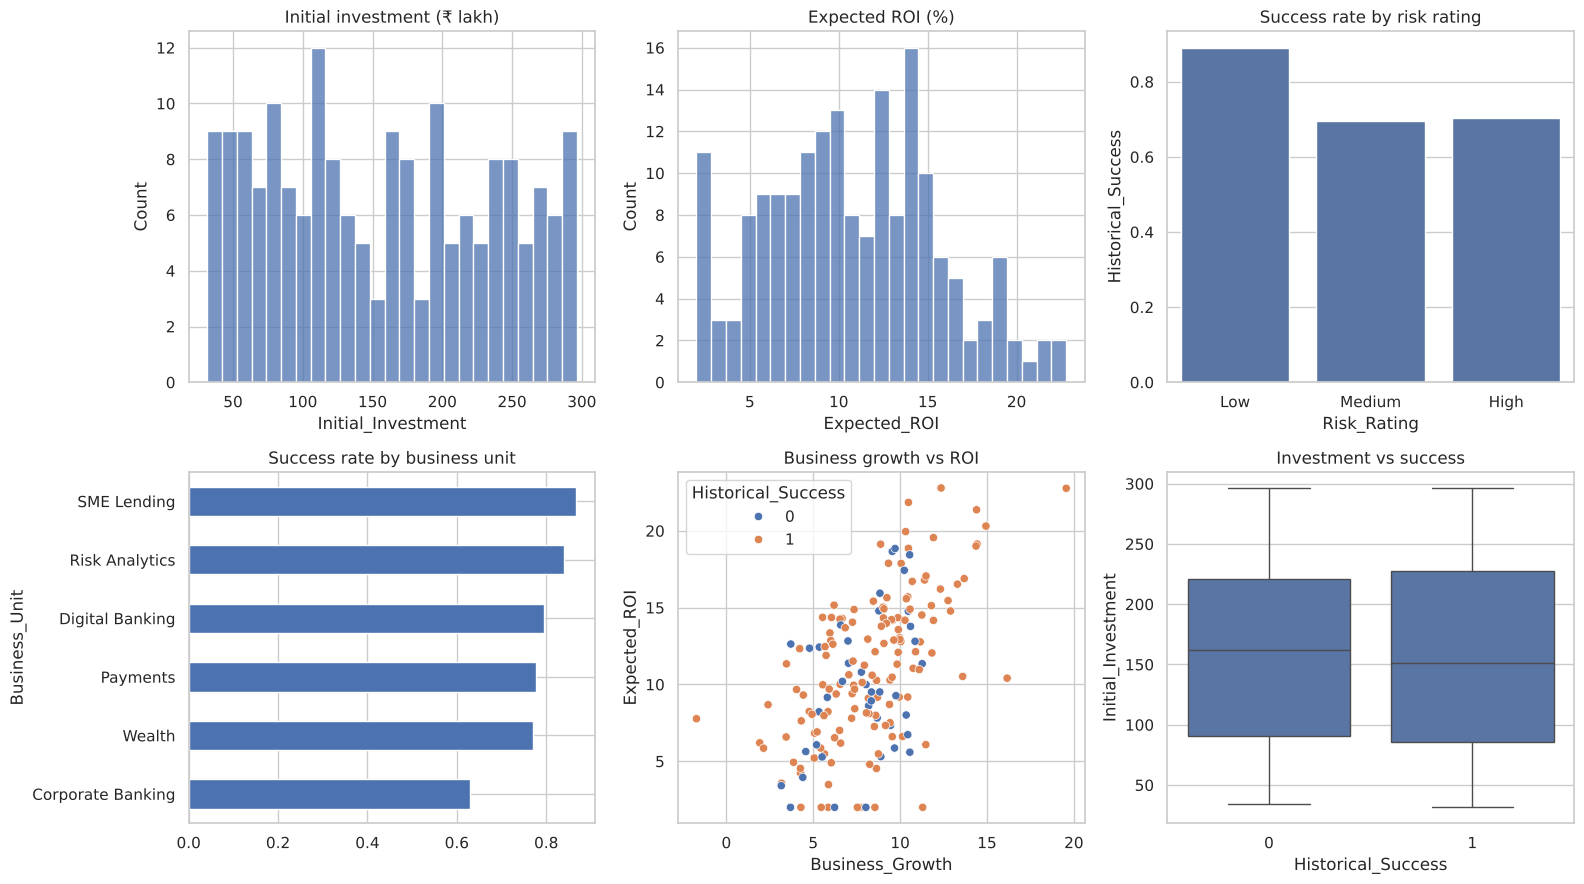

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(16, 9))
sns.histplot(df["Initial_Investment"], bins=25, ax=ax[0, 0]).set_title("Initial investment (₹ lakh)")
sns.histplot(df["Expected_ROI"], bins=25, ax=ax[0, 1]).set_title("Expected ROI (%)")
order = ["Low", "Medium", "High"]
sns.barplot(data=df, x="Risk_Rating", y="Historical_Success", order=order, ax=ax[0, 2], errorbar=None).set_title("Success rate by risk rating")
bu = df.groupby("Business_Unit")["Historical_Success"].mean().sort_values()
bu.plot.barh(ax=ax[1, 0], color="C0").set_title("Success rate by business unit")
sns.scatterplot(data=df, x="Business_Growth", y="Expected_ROI", hue="Historical_Success", ax=ax[1, 1]).set_title("Business growth vs ROI")
sns.boxplot(data=df, x="Historical_Success", y="Initial_Investment", ax=ax[1, 2]).set_title("Investment vs success")
plt.tight_layout(); plt.show()

In [5]:
summary_bu = df.groupby("Business_Unit").agg(n=("Initiative_ID", "count"), success_rate=("Historical_Success", "mean"),
                                            avg_investment=("Initial_Investment", "mean"), avg_roi=("Expected_ROI", "mean")).round(2)
summary_bu.sort_values("success_rate", ascending=False)

,n,success_rate,avg_investment,avg_roi
Business_Unit,,,,
SME Lending,15,0.87,148.53,10.19
Risk Analytics,25,0.84,159.09,9.22
Digital Banking,34,0.79,138.64,12.22
Payments,36,0.78,148.13,10.57
Wealth,35,0.77,167.47,10.81
Corporate Banking,35,0.63,178.06,10.86


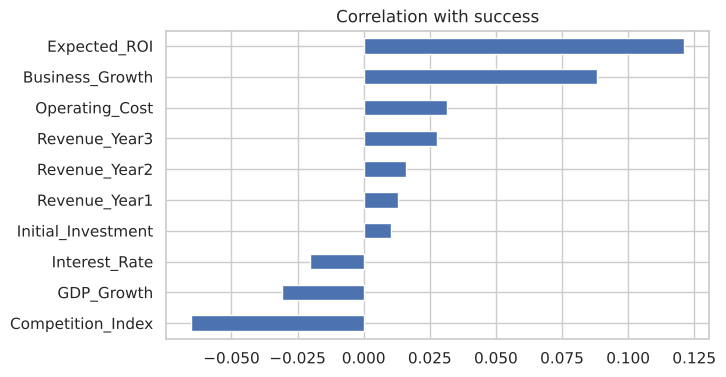

In [6]:
num = df.select_dtypes("number").drop(columns="Initiative_ID")
num.corr()["Historical_Success"].drop("Historical_Success").sort_values().plot.barh(figsize=(7, 4), title="Correlation with success")
plt.show()

**What the EDA says:** Low-risk initiatives succeed most often (~89% vs ~70%). Expected_ROI and Business_Growth have the strongest (but still weak) positive link with success; competition has a negative one. Investment size barely matters. With such weak single-variable signals, expect modest model performance.

## 3. Feature engineering
- Map `Risk_Rating` to an ordered number (Low=0, Medium=1, High=2).
- One-hot encode `Business_Unit`.
- Add finance ratios: **revenue multiple** (3-year revenue ÷ investment) and **operating margin**.
- Drop `Initiative_ID` (an ID carries no information, and using it would be a mistake).

**Leakage check:** `Expected_ROI` is a forecast made *before* the project, so it is allowed. (Its correlation with the realised cash-flow ROI is only ~0.5, so it is not a hidden copy of the outcome.)

In [7]:
X = df.drop(columns=["Initiative_ID", "Historical_Success"]).copy()
y = df["Historical_Success"]
X["Risk_Rating"] = X["Risk_Rating"].map({"Low": 0, "Medium": 1, "High": 2})
rev3 = X[["Revenue_Year1", "Revenue_Year2", "Revenue_Year3"]].sum(axis=1)
X["Revenue_Multiple"] = rev3 / X["Initial_Investment"]
X["Operating_Margin"] = 1 - 3 * X["Operating_Cost"] / rev3
X = pd.get_dummies(X, columns=["Business_Unit"], dtype=float)
X.shape

(180, 19)

## 4. Models and validation
With only 180 rows a single train/test split is unreliable (the test set would hold ~10 failures). We use **repeated stratified 5-fold cross-validation** (5 folds × 10 repeats = 50 scores per model) and compare the mean and spread of ROC-AUC.

Models: a dummy baseline, logistic regression (simple, explainable), random forest and XGBoost (non-linear).

In [8]:
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from xgboost import XGBClassifier

models = {
    "Baseline (always majority)": DummyClassifier(strategy="prior"),
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(C=0.3, max_iter=1000)),
    "Random forest": RandomForestClassifier(n_estimators=400, max_depth=4, min_samples_leaf=5, random_state=SEED),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=2, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=SEED, verbosity=0),
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
scores = {name: cross_val_score(m, X, y, cv=cv, scoring="roc_auc") for name, m in models.items()}
cv_table = pd.DataFrame({k: [v.mean(), v.std()] for k, v in scores.items()}, index=["mean AUC", "std"]).T.round(3)
cv_table

,mean AUC,std
Baseline (always majority),0.500,0.000
Logistic regression,0.545,0.093
Random forest,0.458,0.088
XGBoost,0.493,0.092


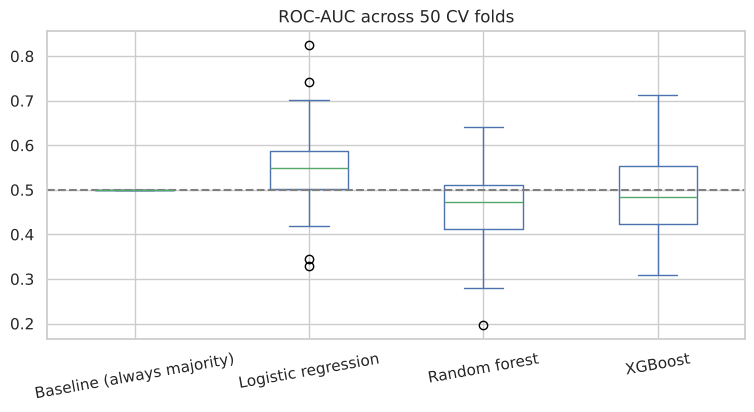

In [9]:
pd.DataFrame(scores).plot.box(figsize=(9, 4), title="ROC-AUC across 50 CV folds", rot=10); plt.axhline(0.5, ls="--", c="grey"); plt.show()

**How to read this:** AUC 0.5 = random guessing, 1.0 = perfect. Logistic regression reaches only ~0.55, and the tree models fall *below* 0.5 because they overfit 180 rows. The spread (±0.09) is larger than the gaps between models.

**Finding for the board:** past success is barely predictable from these characteristics. That is an honest, useful result: P(success) should be a small adjustment, and the funding decision must rest mainly on NPV and risk. NovaFin should also collect richer initiative data (team, execution track record) before trusting a success model.

## 5. Explainability: what makes an initiative succeed?
Logistic-regression coefficients (on standardised features) give direction and strength. SHAP shows the same for the tree model, feature by feature.

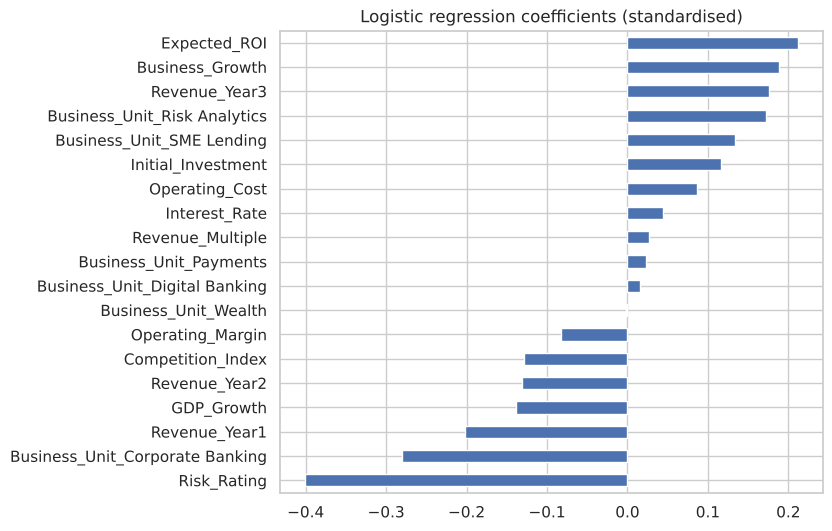

In [10]:
lr = models["Logistic regression"].fit(X, y)
coef = pd.Series(lr[-1].coef_[0], index=X.columns).sort_values()
coef.plot.barh(figsize=(7, 6), title="Logistic regression coefficients (standardised)"); plt.show()

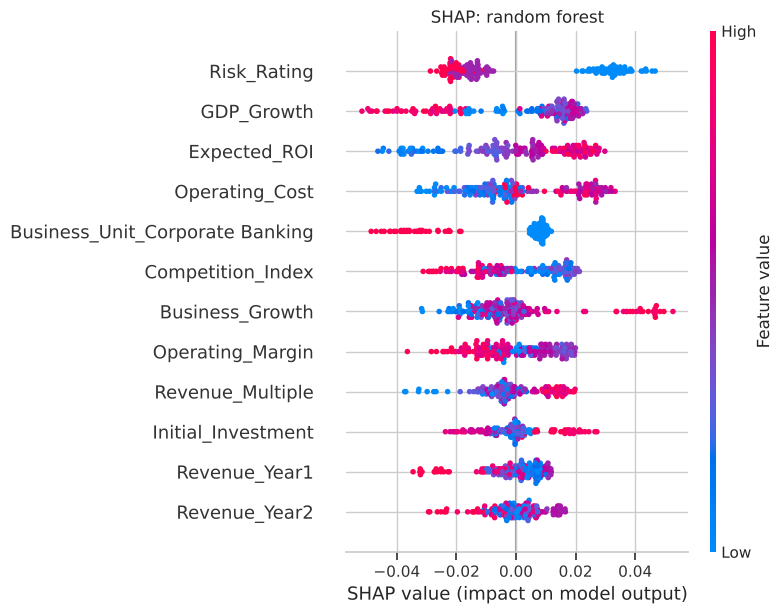

In [11]:
import shap
rf = models["Random forest"].fit(X, y)
sv = shap.TreeExplainer(rf).shap_values(X)
sv = sv[:, :, 1] if np.ndim(sv) == 3 else sv[1]
shap.summary_plot(sv, X, max_display=12, show=False); plt.title("SHAP: random forest"); plt.tight_layout(); plt.show()

## 6. Out-of-fold P(success)
To score every initiative fairly, each one gets its probability from a model that **did not see it in training** (`cross_val_predict`). Otherwise our expected NPV would be over-optimistic.

We use **logistic regression**, the best model in cross-validation. The tree models scored below 0.5: with 180 rows they memorise noise (overfitting).

In [12]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
p_lr = cross_val_predict(models["Logistic regression"], X, y, cv=skf, method="predict_proba")[:, 1]
from sklearn.metrics import roc_auc_score
df["P_Success"] = p_lr
print("Out-of-fold AUC:", round(roc_auc_score(y, df["P_Success"]), 3))

Out-of-fold AUC: 0.574


## 7. NPV and Expected NPV
**Assumptions (state these in the report):**
1. Annual cash flow = Revenue_Year_t − Operating_Cost.
2. **Project life = 5 years**: years 4 and 5 repeat the year-3 cash flow. With only 3 years almost no project pays back its investment (only 3% have positive NPV), which is unrealistic for strategic initiatives.
3. **Units:** all money is in ₹ lakh, as the data README says (100 lakh = 1 crore).
4. **Discount rate** = Interest_Rate + risk premium (Low +2%, Medium +4%, High +6%).

$$NPV = -I_0 + \sum_{t=1}^{5} \frac{CF_t}{(1+r)^t} \qquad ENPV = P(\text{success}) \times NPV$$

In [13]:
PREMIUM = {"Low": 0.02, "Medium": 0.04, "High": 0.06}
def npv(d, life=5, premium=PREMIUM):
    r = d["Interest_Rate"] / 100 + d["Risk_Rating"].map(premium)
    cf = [d[f"Revenue_Year{t}"] - d["Operating_Cost"] for t in (1, 2, 3)]
    cf += [cf[2]] * (life - 3)
    return -d["Initial_Investment"] + sum(cf[t] / (1 + r) ** (t + 1) for t in range(life))

df["Discount_Rate"] = df["Interest_Rate"] / 100 + df["Risk_Rating"].map(PREMIUM)
df["NPV"] = npv(df)
df["ENPV"] = df["P_Success"] * df["NPV"]
df[["Initiative_ID", "Business_Unit", "Initial_Investment", "Risk_Rating", "P_Success", "NPV", "ENPV"]].sort_values("ENPV", ascending=False).head(10).round(2)

,Initiative_ID,Business_Unit,Initial_Investment,Risk_Rating,P_Success,NPV,ENPV
74,1075,Wealth,220.85,Low,0.88,224.35,197.61
30,1031,Wealth,194.04,Medium,0.74,195.45,143.79
2,1003,Wealth,227.64,High,0.77,162.95,125.81
25,1026,Payments,242.00,Low,0.84,148.63,124.75
33,1034,Risk Analytics,286.20,Low,0.87,142.80,124.65
178,1179,Digital Banking,282.92,High,0.76,155.89,118.07
73,1074,Corporate Banking,250.17,Medium,0.76,137.66,104.62
134,1135,Wealth,284.59,Medium,0.79,107.42,85.26
176,1177,SME Lending,216.55,Low,0.95,89.87,85.06
153,1154,Wealth,162.15,Medium,0.65,128.93,83.20


**Sensitivity:** how many initiatives have positive NPV under different project lives? This shows the board how much the answer depends on our assumption.

In [14]:
sens = pd.DataFrame({f"{life}-year life": [(npv(df, life) > 0).mean(), npv(df, life).median()] for life in (3, 5, 7)},
                    index=["share with NPV > 0", "median NPV"]).round(2)
sens

,3-year life,5-year life,7-year life
share with NPV > 0,0.03,0.36,0.61
median NPV,-65.76,-18.27,15.16


## 8. Decision: Fund / Review / Reject
Rules (thresholds are our judgement; justify them in the report):
- **Fund:** ENPV > 0, P(success) ≥ 0.70 and risk Low or Medium. High expected value and acceptable risk.
- **Review:** ENPV > 0 but High risk or P(success) < 0.70. Potentially attractive but uncertain.
- **Reject:** ENPV ≤ 0. Low expected value.

In [15]:
def decide(r):
    if r["ENPV"] <= 0:
        return "Reject"
    if r["Risk_Rating"] == "High" or r["P_Success"] < 0.70:
        return "Review"
    return "Fund"
df["Decision"] = df.apply(decide, axis=1)
dec = df.groupby("Decision").agg(n=("Initiative_ID", "count"), investment=("Initial_Investment", "sum"), total_ENPV=("ENPV", "sum")).round(1)
dec

,n,investment,total_ENPV
Decision,,,
Fund,45,6730.1,1703.2
Reject,115,18489.4,-5625.4
Review,20,3125.3,650.6


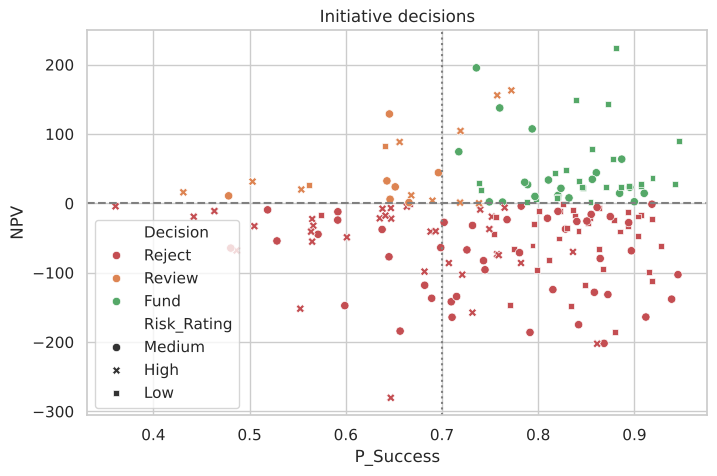

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=df, x="P_Success", y="NPV", hue="Decision", style="Risk_Rating", palette={"Fund": "C2", "Review": "C1", "Reject": "C3"}, ax=ax)
ax.axhline(0, c="grey", ls="--"); ax.axvline(0.70, c="grey", ls=":"); ax.set_title("Initiative decisions"); plt.show()

In [17]:
by_bu = (df.pivot_table(index="Business_Unit", columns="Decision", values="Initiative_ID", aggfunc="count", fill_value=0)
         .join(df[df.Decision == "Fund"].groupby("Business_Unit").agg(Fund_investment=("Initial_Investment", "sum"), Fund_ENPV=("ENPV", "sum")))
         .fillna(0).round(1).sort_values("Fund_ENPV", ascending=False))
by_bu

,Fund,Reject,Review,Fund_investment,Fund_ENPV
Business_Unit,,,,,
Wealth,9,22,4,1533.3,574.4
Payments,12,23,1,1673.1,355.0
Risk Analytics,7,18,0,1305.8,280.1
Digital Banking,10,20,4,1330.4,253.5
Corporate Banking,3,22,10,501.3,121.0
SME Lending,4,10,1,386.2,119.2


## 9. Save outputs for Module 9 (integrated allocation)

In [18]:
cols = ["Initiative_ID", "Business_Unit", "Initial_Investment", "Risk_Rating", "P_Success", "Discount_Rate", "NPV", "ENPV", "Decision"]
df[cols].round(4).to_csv(OUT / "m1_initiatives.csv", index=False)
by_bu.to_csv(OUT / "m1_by_business_unit.csv")
print("Saved", OUT / "m1_initiatives.csv")

Saved ../outputs/m1_initiatives.csv


## 10. Conclusions
1. **Success is hard to predict:** best cross-validated AUC ≈ 0.55 (logistic regression). Low risk rating, higher expected ROI and business growth push success up; competition pushes it down.
2. **Financials drive the decision:** under a 5-year life, about a third of initiatives have positive NPV. The result is sensitive to project life, so state it clearly.
3. **Recommendation:** fund the initiatives in the *Fund* group (see table above), send *Review* initiatives to a committee with extra due diligence, and reject the rest. Wealth, Payments and Digital Banking carry the most fundable expected value.
4. **Limits:** 180 rows, synthetic data, NPV depends on assumed life and discount premiums.